# RBI banking data for India

District deposits and credit of scheduled commercial banks, district credit by bank group and borrower occupation, and national credit by non-bank financial companies, from the Reserve Bank of India. District figures are mapped onto GADM 4.1 district boundaries.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import climate_risk.data

from climate_risk.data.gadm import administered_territories, load_units_in_country
from climate_risk.data.rbi import (load_rbi_district_bank_credit,
                                   load_rbi_district_deposit_types,
                                   load_rbi_district_deposits_and_credit,
                                   load_rbi_nbfc_sector_credit)
from climate_risk.plotting import configure_plot_style, prepare_gridspec_figure

configure_plot_style(add_grid=True)
cache_dir = Path.cwd().parents[3] / "data"

## District boundaries

GADM 4.1 districts (level 2) and states (level 1), including the parts of Jammu and Kashmir, Ladakh, Himachal Pradesh, Uttarakhand and Arunachal Pradesh that GADM files under disputed-territory codes. The crosswalk `rbi_district_gadm.csv` links each RBI district to the GADM districts it lies in. A district created after GADM's boundaries is linked to the district it was carved from, so its amounts are pooled with its parent's on the maps, and a district linked to several GADM districts has its amounts split equally among them. Ratios are computed after pooling. Gray marks a district with no figures in the statement mapped.

In [2]:
gadm_codes = ("IND", *administered_territories(iso="IND", cache_dir=cache_dir))
gadm_states = pd.concat([load_units_in_country(iso=code, level=1, cache_dir=cache_dir) for code in gadm_codes])
gadm_districts = pd.concat([load_units_in_country(iso=code, level=2, cache_dir=cache_dir) for code in gadm_codes])

crosswalk = pd.read_csv(Path(climate_risk.data.__file__).parent / "rbi_district_gadm.csv")
crosswalk["weight"] = 1 / crosswalk.groupby(["rbi_state", "rbi_district"])["gid"].transform("size")

In [3]:
PANEL_TITLE_SIZE = 12
FIGURE_TITLE_SIZE = 15


def plot_district_map(ax, values, title, label, cmap="viridis"):
    """Color each GADM district by `values`, a Series indexed by gid, titled `title` with `label` on the colorbar."""
    low, high = values.quantile([0.02, 0.98])
    colored = gadm_districts.merge(values.rename("value"),
                                   left_on="gid",
                                   right_index=True)

    gadm_states.plot(ax=ax,
                     color="0.85",
                     edgecolor="white",
                     linewidth=0.3)
    colored.plot(ax=ax,
                 column="value",
                 cmap=cmap,
                 vmin=low,
                 vmax=high,
                 linewidth=0.1,
                 edgecolor="white",
                 legend=True,
                 legend_kwds={"label": label, "shrink": 0.6})
    ax.set_title(title, loc="left", fontsize=PANEL_TITLE_SIZE)
    ax.set_axis_off()


def on_gadm(amounts):
    """Sum additive `amounts`, indexed by RBI (state, district), onto the GADM districts the crosswalk links them to."""
    frame = amounts.reset_index().set_axis(["rbi_state", "rbi_district", *amounts.columns], axis=1)
    frame[["rbi_state", "rbi_district"]] = frame[["rbi_state", "rbi_district"]].astype(str)
    linked = crosswalk.merge(frame, on=["rbi_state", "rbi_district"])

    return linked[list(amounts.columns)].mul(linked["weight"], axis=0).groupby(linked["gid"]).sum()

## 1. District deposits and credit

Statement 4A: reporting offices, aggregate deposits and credit of scheduled commercial banks in each district, at each fiscal year end.

In [4]:
deposits_and_credit = load_rbi_district_deposits_and_credit(cache_dir)
deposits_and_credit.head()

reporting_offices  deposits  \
region         state        district    date                                  
CENTRAL REGION CHHATTISGARH BALOD       2023Q1              86.00   3406.94   
                                        2024Q1              87.00   3800.97   
                                        2025Q1              89.00   4152.30   
                                        2026Q1              90.00   4527.48   
                            BALODABAZAR 2023Q1             100.00   4734.01   

                                                credit  
region         state        district    date            
CENTRAL REGION CHHATTISGARH BALOD       2023Q1 1358.66  
                                        2024Q1 1613.85  
                                        2025Q1 1891.33  
                                        2026Q1 2138.98  
                            BALODABAZAR 2023Q1 2833.49

In [5]:
pd.Series({"districts": deposits_and_credit.index.droplevel("date").nunique(),
           "states": deposits_and_credit.index.unique("state").size,
           "quarters": deposits_and_credit.index.unique("date").size,
           "first quarter": deposits_and_credit.index.unique("date").min(),
           "last quarter": deposits_and_credit.index.unique("date").max()},
          name="Statement 4A").to_frame()

,Statement 4A
districts,767
states,36
quarters,4
first quarter,2023Q1
last quarter,2026Q1


In [6]:
deposits_and_credit.groupby("date").sum()

,reporting_offices,deposits,credit
date,,,
2023Q1,154771.00,18740760.07,14138152.18
2024Q1,159110.00,21251772.60,16798464.10
2025Q1,163702.00,23449772.53,18648073.59
2026Q1,168407.00,26074770.14,21340074.73


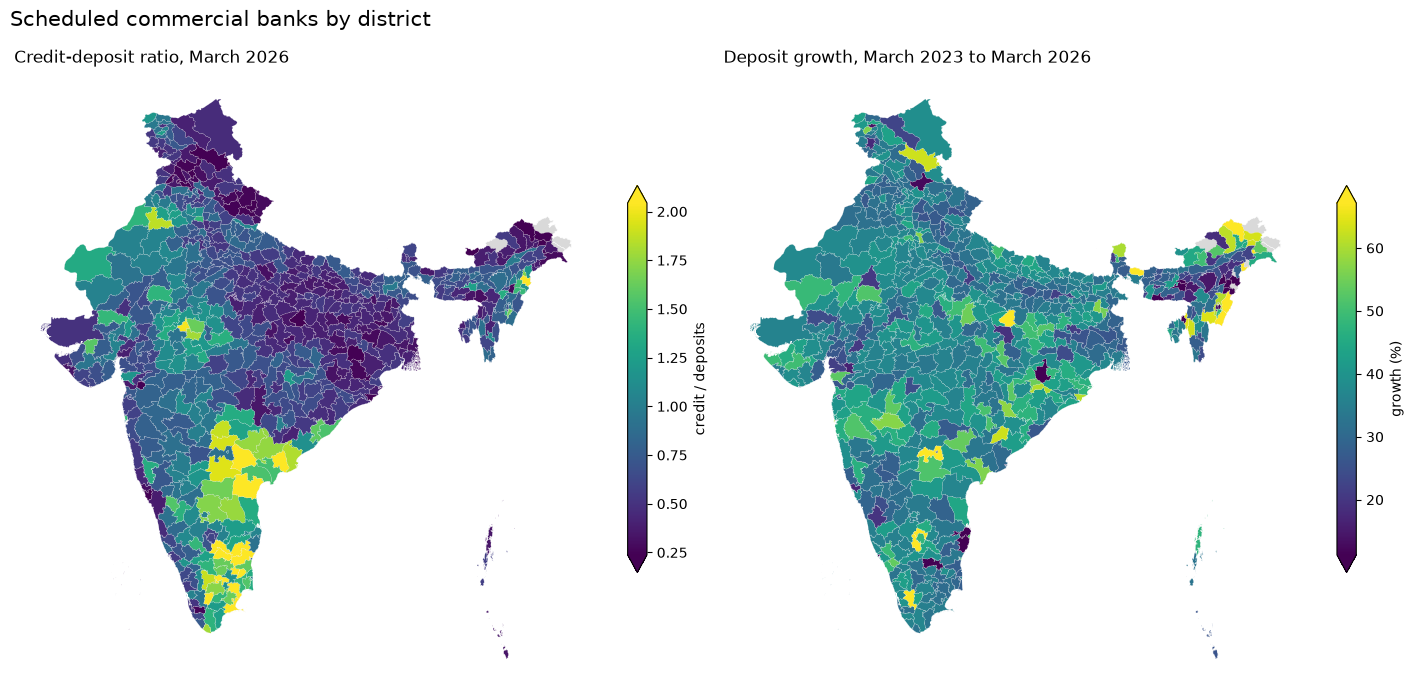

In [7]:
latest = deposits_and_credit.xs(pd.Period("2026Q1"), level="date").droplevel("region")
first = deposits_and_credit.xs(pd.Period("2023Q1"), level="date").droplevel("region")
latest_on_gadm = on_gadm(latest[["deposits", "credit"]])
first_on_gadm = on_gadm(first[["deposits"]])

fig, axes = plt.subplots(ncols=2,
                         figsize=(14, 7),
                         layout="constrained")
plot_district_map(ax=axes[0],
                  values=latest_on_gadm["credit"] / latest_on_gadm["deposits"],
                  title="Credit-deposit ratio, March 2026",
                  label="credit / deposits")
plot_district_map(ax=axes[1],
                  values=100 * (latest_on_gadm["deposits"] / first_on_gadm["deposits"] - 1),
                  title="Deposit growth, March 2023 to March 2026",
                  label="growth (%)")
fig.suptitle("Scheduled commercial banks by district", x=0.0, ha="left", fontsize=FIGURE_TITLE_SIZE);

Banks lend out 82% of their deposits nationally but 65% in the median district, and a fifth of districts lend more than they take in. Credit-deposit ratios above 1.5 cluster in Telangana, Andhra Pradesh and Tamil Nadu, while most of the north, east and northeast lend out less than half their deposits. Deposits grew 39% nationally from March 2023 to March 2026, and half of all districts grew between 30% and 40%.

## 2. District deposits by account type

Statement 4B: the same deposits split into current, savings and term accounts.

In [8]:
deposit_types = load_rbi_district_deposit_types(cache_dir)
deposit_types.head()

current_deposits  \
region         state        district    date                       
CENTRAL REGION CHHATTISGARH BALOD       2023Q1            176.09   
                                        2024Q1            173.87   
                                        2025Q1            173.84   
                                        2026Q1            202.13   
                            BALODABAZAR 2023Q1            268.34   

                                                savings_deposits  \
region         state        district    date                       
CENTRAL REGION CHHATTISGARH BALOD       2023Q1           1939.45   
                                        2024Q1           2152.64   
                                        2025Q1           2328.38   
                                        2026Q1           2462.14   
                            BALODABAZAR 2023Q1           2831.87   

                                                term_deposits  deposits  
region         state        district    date                             
CENTRAL REGION CHHATTISGARH BALOD       2023Q1        1291.40   3406.94  
                                        2024Q1        1474.45   3800.97  
                                        2025Q1        1650.08   4152.30  
                                        2026Q1        1863.21   4527.48  
                            BALODABAZAR 2023Q1        1633.80   4734.01

In [9]:
totals = deposit_types.groupby("date").sum()
totals[["current_deposits", "savings_deposits", "term_deposits"]].div(totals["deposits"], axis=0)

,current_deposits,savings_deposits,term_deposits
date,,,
2023Q1,0.10,0.34,0.56
2024Q1,0.10,0.31,0.59
2025Q1,0.10,0.30,0.61
2026Q1,0.10,0.29,0.61


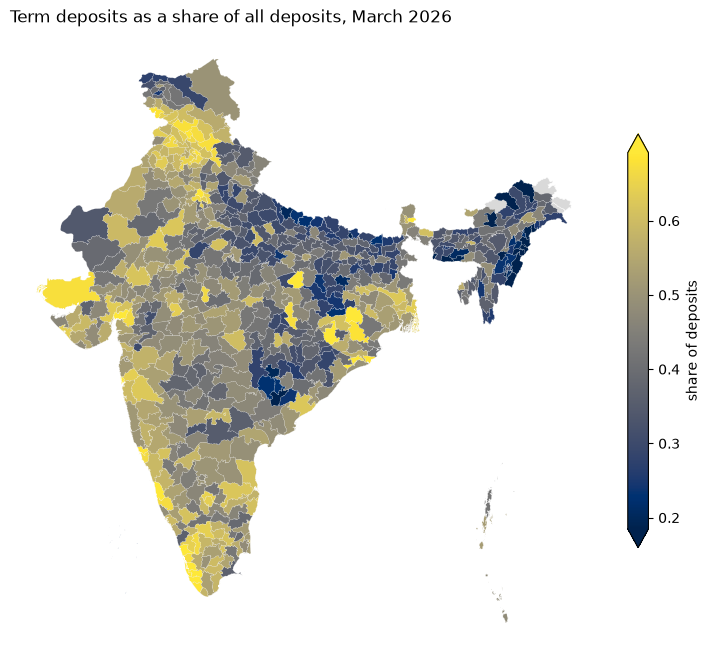

In [10]:
latest_types = deposit_types.xs(pd.Period("2026Q1"), level="date").droplevel("region")
types_on_gadm = on_gadm(latest_types[["term_deposits", "deposits"]])

fig, ax = plt.subplots(figsize=(7, 7), layout="constrained")
plot_district_map(ax=ax,
                  values=types_on_gadm["term_deposits"] / types_on_gadm["deposits"],
                  title="Term deposits as a share of all deposits, March 2026",
                  label="share of deposits",
                  cmap="cividis")

Term deposits are 61% of national deposits but 45% in the median district, since the districts holding the most deposits have the highest term shares. The share is highest in Kerala, Punjab, Haryana and Kutch, and lowest across the northeast, the Gangetic plain and Chhattisgarh.

## 3. Bank credit by district, bank group and occupation

BSR-1: one record per year, district, population group, bank group and occupation, with accounts, credit limit and amount outstanding.

In [11]:
bank_credit = load_rbi_district_bank_credit(cache_dir)
bank_credit.head()

,year,region,state,district,population_group,bank_group,occupation_group,occupation_subgroup,accounts,credit_limit,amount_outstanding
0,2026,CENTRAL REGION,CHHATTISGARH,BALOD,RURAL,PUBLIC SECTOR BANKS,V. PERSONAL LOANS,3. VEHICLES,566.00,43.70,29.19
1,2026,CENTRAL REGION,CHHATTISGARH,BALOD,RURAL,PUBLIC SECTOR BANKS,V. PERSONAL LOANS,4. EDUCATION,89.00,4.03,2.76
2,2026,CENTRAL REGION,CHHATTISGARH,BALOD,RURAL,PUBLIC SECTOR BANKS,V. PERSONAL LOANS,6. OTHERS,4725.00,261.18,193.88
3,2026,CENTRAL REGION,CHHATTISGARH,BALOD,RURAL,PUBLIC SECTOR BANKS,V. PERSONAL LOANS,1. HOUSING,507.00,91.01,66.53
4,2026,CENTRAL REGION,CHHATTISGARH,BALOD,RURAL,PUBLIC SECTOR BANKS,V. PERSONAL LOANS,2. CONSUMER DURABLES,25.00,0.72,0.45


In [12]:
pd.Series({"records": len(bank_credit),
           "years": f"{bank_credit['year'].min()} to {bank_credit['year'].max()}",
           **{column: bank_credit[column].cat.categories.size
              for column in ["state", "district", "population_group", "bank_group", "occupation_group", "occupation_subgroup"]}},
          name="BSR-1").to_frame()

,BSR-1
records,2244707
years,2010 to 2026
state,40
district,825
population_group,4
bank_group,7
occupation_group,8
occupation_subgroup,33


In [13]:
LAKH_CRORE = 1e5

credit_by_bank_group = bank_credit.pivot_table(index="year",
                                               columns="bank_group",
                                               values="amount_outstanding",
                                               aggfunc="sum",
                                               observed=True) / LAKH_CRORE
credit_by_occupation = bank_credit.pivot_table(index="year",
                                               columns="occupation_group",
                                               values="amount_outstanding",
                                               aggfunc="sum",
                                               observed=True) / LAKH_CRORE

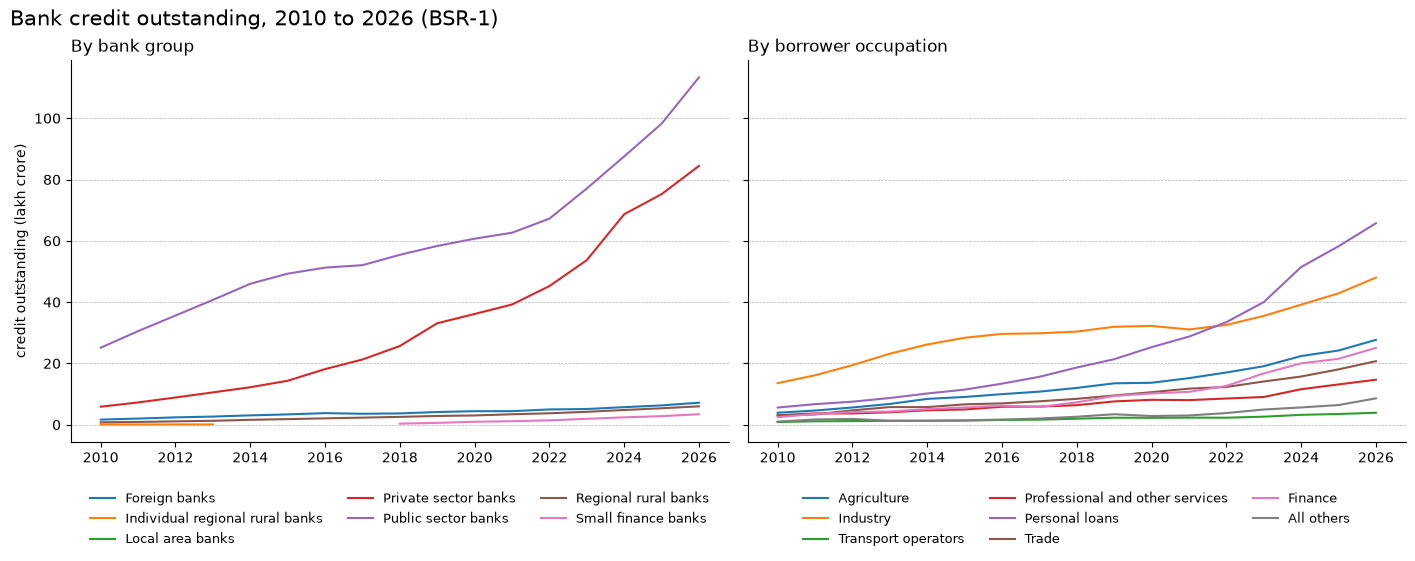

In [14]:
fig, axes = plt.subplots(ncols=2,
                         figsize=(14, 5.5),
                         sharey=True,
                         layout="constrained")
for ax, table, title in zip(axes,
                            [credit_by_bank_group, credit_by_occupation],
                            ["By bank group", "By borrower occupation"],
                            strict=True):
    labels = table.columns.astype(str).str.replace(pat=r"^[IVX]+\.\s*", repl="", regex=True).str.capitalize()
    table.set_axis(labels, axis=1).plot(ax=ax, lw=1.5, legend=False)
    ax.grid(visible=False, axis="x")
    ax.set(xlabel="", ylabel="credit outstanding (lakh crore)")
    ax.set_title(title, loc="left", fontsize=PANEL_TITLE_SIZE)
    ax.legend(loc="upper center",
              bbox_to_anchor=(0.5, -0.1),
              ncol=3,
              frameon=False,
              fontsize=9)
fig.suptitle("Bank credit outstanding, 2010 to 2026 (BSR-1)", x=0.0, ha="left", fontsize=FIGURE_TITLE_SIZE);

Public sector banks' credit grew from 25 to 113 lakh crore between 2010 and 2026, and private sector banks' from 6 to 84 lakh crore, so the private sector's share of bank credit rose from 18% to 39%. Personal loans overtook industry in 2022 and reached 66 lakh crore in 2026, against 48 lakh crore for industry.

In [15]:
credit_2026 = bank_credit[bank_credit["year"] == 2026]
by_district = ["state", "district"]

district_amounts = pd.DataFrame({
    "all_credit": credit_2026.groupby(by_district, observed=True)["amount_outstanding"].sum(),
    "agriculture": (credit_2026[credit_2026["occupation_group"] == "I. AGRICULTURE"]
                    .groupby(by_district, observed=True)["amount_outstanding"].sum()),
    "public_sector": (credit_2026[credit_2026["bank_group"] == "PUBLIC SECTOR BANKS"]
                      .groupby(by_district, observed=True)["amount_outstanding"].sum()),
}).fillna(0.0)
credit_on_gadm = on_gadm(district_amounts)

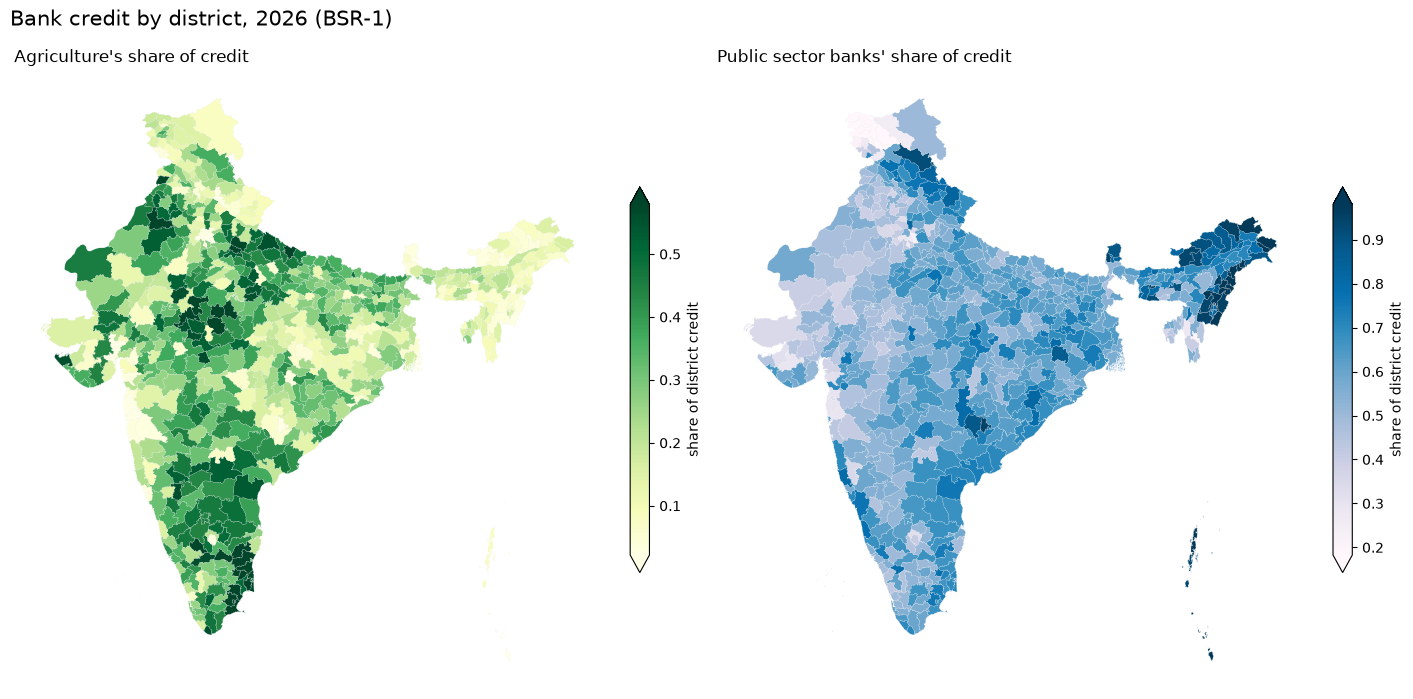

In [16]:
fig, axes = plt.subplots(ncols=2,
                         figsize=(14, 7),
                         layout="constrained")
plot_district_map(ax=axes[0],
                  values=credit_on_gadm["agriculture"] / credit_on_gadm["all_credit"],
                  title="Agriculture's share of credit",
                  label="share of district credit",
                  cmap="YlGn")
plot_district_map(ax=axes[1],
                  values=credit_on_gadm["public_sector"] / credit_on_gadm["all_credit"],
                  title="Public sector banks' share of credit",
                  label="share of district credit",
                  cmap="PuBu")
fig.suptitle("Bank credit by district, 2026 (BSR-1)", x=0.0, ha="left", fontsize=FIGURE_TITLE_SIZE);

Agriculture takes 25% of credit in the median district but 13% nationally, because its share is small in the large urban districts that hold most credit. It is highest, 40 to 55%, across Uttar Pradesh, Madhya Pradesh, Rajasthan and Tamil Nadu, and lowest in the northeast. Public sector banks hold 53% of national credit and 60% in the median district, rising above 90% in much of the northeast.

## 4. Where each bank group lends

Each bank group's share of a district's outstanding credit in 2026, from BSR-1. Each map has its own color scale.

In [17]:
group_credit_on_gadm = on_gadm(credit_2026.groupby([*by_district, "bank_group"], observed=True)["amount_outstanding"].sum()
                               .unstack("bank_group", fill_value=0.0))
bank_group_shares = group_credit_on_gadm.div(group_credit_on_gadm.sum(axis=1), axis=0)

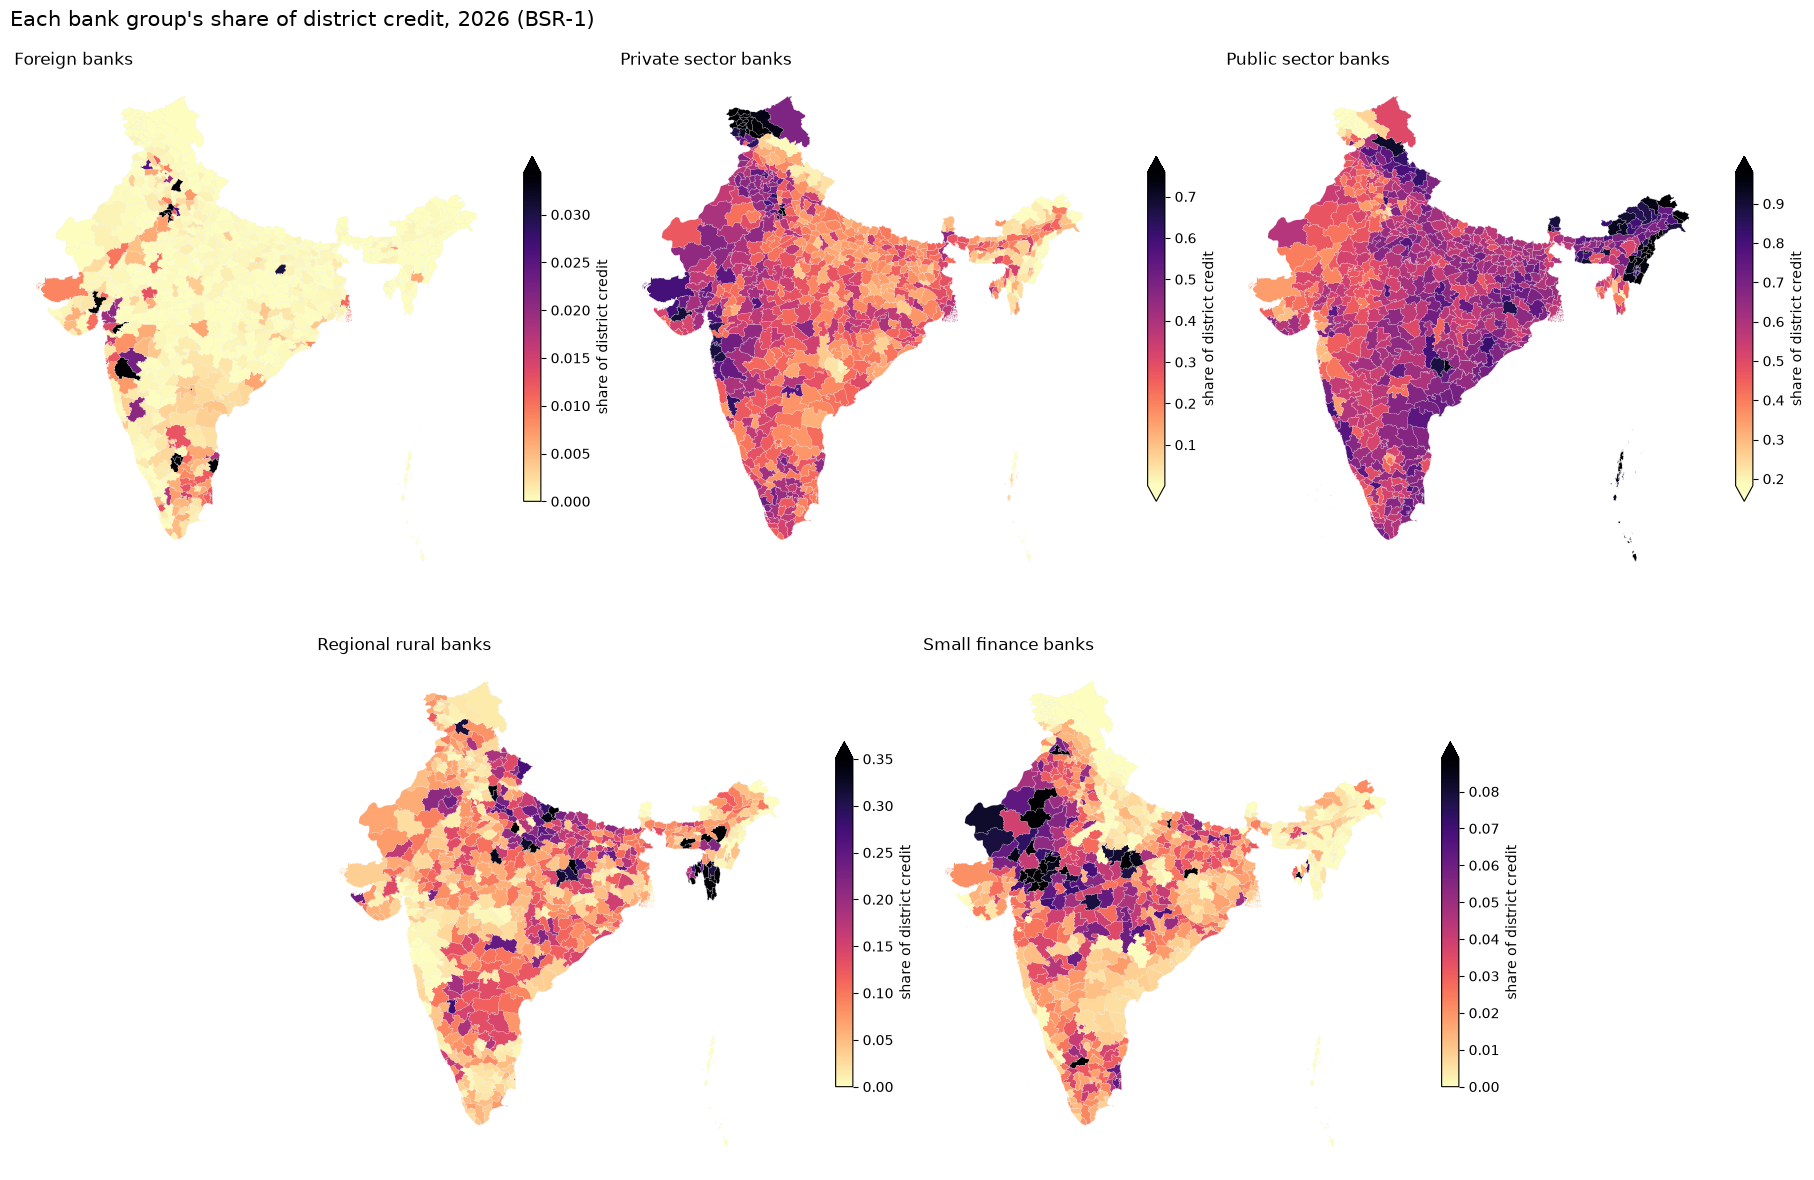

In [18]:
fig = plt.figure(figsize=(18, 12), layout="constrained")
gs, plot_locs = prepare_gridspec_figure(n_cols=3, n_plots=bank_group_shares.shape[1], figure=fig)

for (row_slice, col_slice), bank_group in zip(plot_locs, bank_group_shares.columns, strict=True):
    plot_district_map(ax=fig.add_subplot(gs[row_slice, col_slice]),
                      values=bank_group_shares[bank_group],
                      title=str(bank_group).capitalize(),
                      label="share of district credit",
                      cmap="magma_r")

fig.suptitle("Each bank group's share of district credit, 2026 (BSR-1)", x=0.0, ha="left", fontsize=FIGURE_TITLE_SIZE);

Each group lends mainly in its own part of the country. Public sector banks hold over 80% of credit across most of the northeast and in the Himalayan districts of Himachal Pradesh and Uttarakhand. Private sector banks are strongest in the west and in Jammu and Kashmir. Regional rural banks reach 20 to 35% of credit in parts of Uttar Pradesh, Bihar, Assam and Tripura, small finance banks 5 to 9% in Rajasthan and Madhya Pradesh, and foreign banks exceed 1% only in a handful of urban districts.

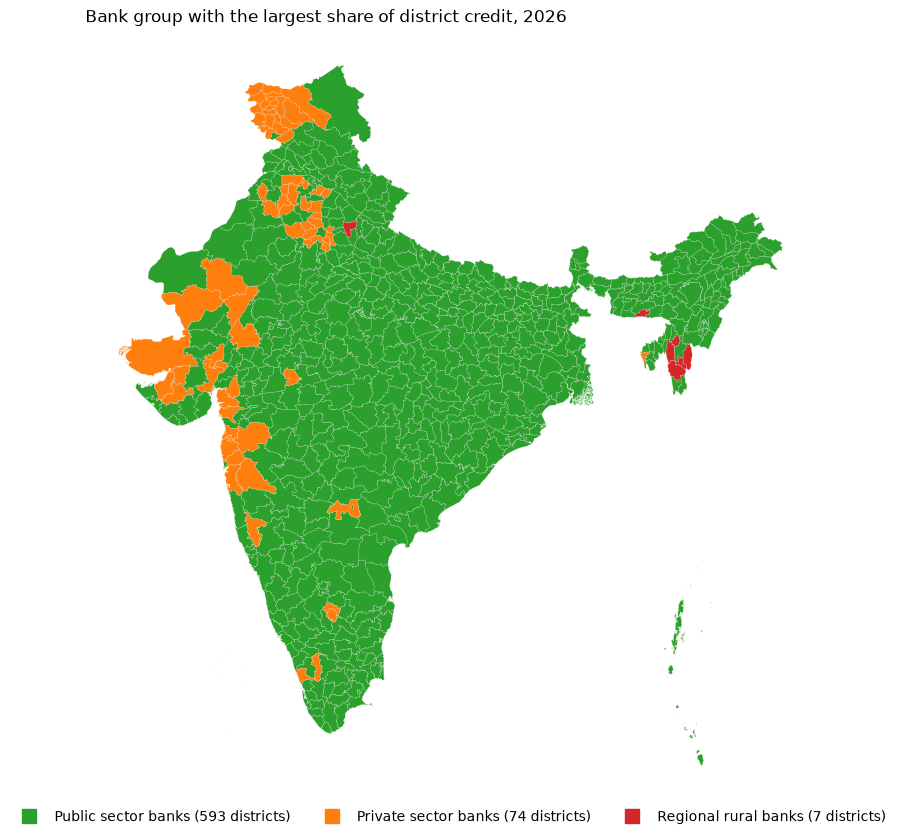

In [19]:
GROUP_COLORS = dict(zip(bank_group_shares.columns.astype(str).str.capitalize(), plt.get_cmap("tab10").colors, strict=False))

largest_group = bank_group_shares.idxmax(axis=1).astype(str).str.capitalize()
colored = gadm_districts.merge(largest_group.rename("largest_group"),
                               left_on="gid",
                               right_index=True)

fig, ax = plt.subplots(figsize=(8, 8), layout="constrained")
gadm_states.plot(ax=ax,
                 color="0.85",
                 edgecolor="white",
                 linewidth=0.3)
colored.plot(ax=ax,
             color=colored["largest_group"].map(GROUP_COLORS),
             edgecolor="white",
             linewidth=0.1)
ax.set_axis_off()
ax.set_title("Bank group with the largest share of district credit, 2026", loc="left", fontsize=PANEL_TITLE_SIZE)

counts = largest_group.value_counts()
handles = [plt.Line2D([], [], color=GROUP_COLORS[group], marker="s", markersize=10, lw=0, label=f"{group} ({count} districts)")
           for group, count in counts.items()]
fig.legend(handles=handles,
           loc="lower center",
           bbox_to_anchor=(0.5, -0.04),
           ncol=len(handles),
           frameon=False);

Public sector banks hold the largest share of credit in 593 of the 674 districts, private sector banks in 74 and regional rural banks in 7. The private sector districts form a belt through Gujarat, eastern Rajasthan, Punjab, Haryana and western Maharashtra, and cover most of Jammu and Kashmir, whose own J&K Bank is classed as a private sector bank. Regional rural banks lead only in Tripura, Assam and one district of Uttarakhand.

## 5. NBFC credit by sector

Table VI.5: credit extended by non-bank financial companies to each sector, at half-year ends. The table's totals and subtotals are kept as items.

In [20]:
nbfc_credit = load_rbi_nbfc_sector_credit(cache_dir)
nbfc_credit.head()

credit
item                    date              
Gross Advances (1 to 5) 2019-03 2295371.00
                        2019-09 2354211.00
                        2020-03 2463943.00
                        2021-03 2709196.00
                        2021-09 2661782.00

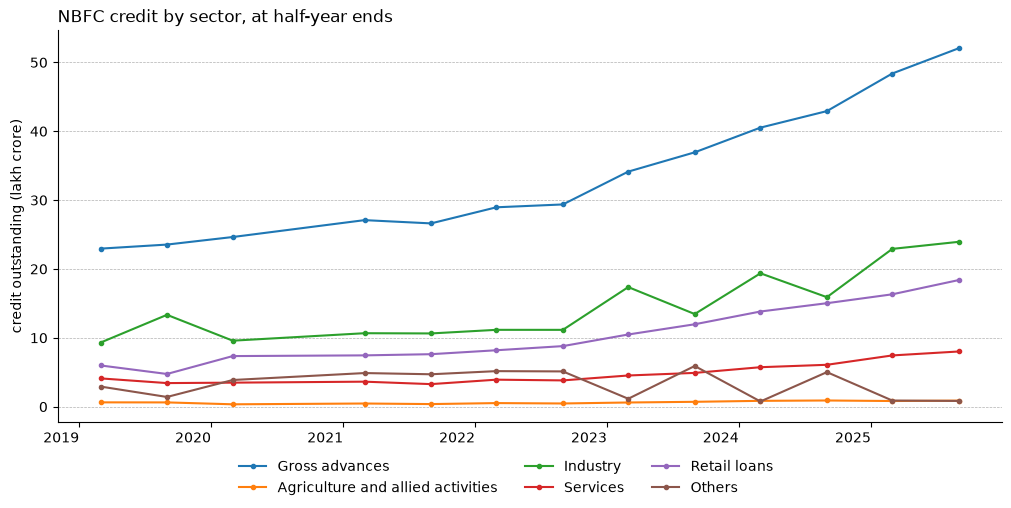

In [21]:
top_level_items = [item for item in nbfc_credit.index.unique("item")
                   if item.startswith(("Gross Advances", "1. ", "2. ", "3. ", "4. ", "5. "))]
top_level_credit = nbfc_credit["credit"].unstack("item")[top_level_items] / LAKH_CRORE
sector_names = (top_level_credit.columns.str.replace(pat=r"^\d+\.\s*|\s*\(.*\)$", repl="", regex=True)
                .str.capitalize())

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
top_level_credit.set_axis(sector_names, axis=1).set_axis(top_level_credit.index.to_timestamp()).plot(ax=ax,
                                                                                                     lw=1.5,
                                                                                                     marker="o",
                                                                                                     markersize=3,
                                                                                                     legend=False,
                                                                                                     rot=0)
ax.grid(visible=False, axis="x")
ax.set(xlabel="", ylabel="credit outstanding (lakh crore)")
ax.set_title("NBFC credit by sector, at half-year ends", loc="left", fontsize=PANEL_TITLE_SIZE)
fig.legend(loc="outside lower center",
           ncol=3,
           frameon=False);

NBFC credit more than doubled, from 23 lakh crore in March 2019 to 52 lakh crore in September 2025, with retail loans growing steadily throughout. From 2022 industry jumps in every March report and falls in every September one, and the "others" sector mirrors it, so the half-year reports appear to classify part of industry credit differently. Industry and others are comparable only between reports at the same half-year end.